# Logistic Regression with ROC Curve and ROC AUC score

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


from sklearn.model_selection import train_test_split
from collections import Counter
from sklearn.datasets import make_classification


from sklearn.metrics import roc_curve, roc_auc_score

In [2]:
X, y = make_classification(
    n_samples = 1000,
    n_classes = 2,
    random_state = 1
)

<Axes: xlabel='0', ylabel='1'>

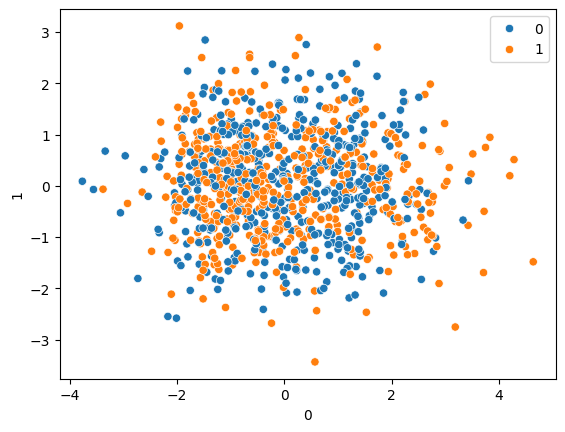

In [3]:
sns.scatterplot(x = pd.DataFrame(X)[0], y = pd.DataFrame(X)[1], hue = y)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size = 0.2, 
    random_state = 0
)

In [5]:
dummy_model_prob = [0 for _ in range(len(y_test))]
dummy_model_prob

[0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [6]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [7]:
model_prob = model.predict_proba(X_test)
model_prob

array([[7.56386163e-02, 9.24361384e-01],
       [1.32569178e-01, 8.67430822e-01],
       [9.73379100e-01, 2.66208996e-02],
       [2.12950676e-02, 9.78704932e-01],
       [4.49010359e-02, 9.55098964e-01],
       [1.96053391e-01, 8.03946609e-01],
       [9.94129991e-01, 5.87000946e-03],
       [9.41533994e-01, 5.84660055e-02],
       [9.52364348e-03, 9.90476357e-01],
       [5.46607262e-01, 4.53392738e-01],
       [9.84678576e-01, 1.53214236e-02],
       [8.17423312e-02, 9.18257669e-01],
       [1.88256919e-01, 8.11743081e-01],
       [6.47469946e-03, 9.93525301e-01],
       [9.56921927e-01, 4.30780728e-02],
       [9.42246417e-01, 5.77535825e-02],
       [2.90932210e-02, 9.70906779e-01],
       [8.14641889e-01, 1.85358111e-01],
       [9.57867369e-01, 4.21326315e-02],
       [4.34402198e-02, 9.56559780e-01],
       [9.95630277e-01, 4.36972339e-03],
       [1.30708022e-01, 8.69291978e-01],
       [2.08937668e-01, 7.91062332e-01],
       [4.39641856e-01, 5.60358144e-01],
       [4.082847

In [8]:
## let's focus on the positive outcome
model_prob = model_prob[:, 1]

In [9]:
## let's calculate the scores
dummy_model_auc = roc_auc_score(y_test, dummy_model_prob)
model_auc = roc_auc_score(y_test, model_prob)
print(dummy_model_auc)
print(model_auc)

0.5
0.916766826923077


In [10]:
dummy_fpr, dummy_tpr, _ = roc_curve(y_test, dummy_model_prob)
model_fpr, model_tpr, threshold = roc_curve(y_test, model_prob) 

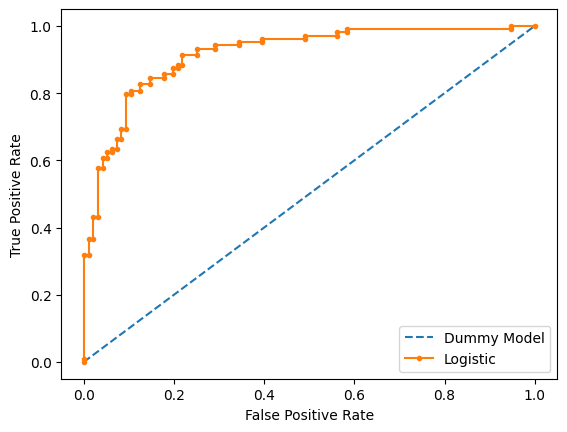

In [11]:
plt.plot(dummy_fpr, dummy_tpr, linestyle = '--', label='Dummy Model')
plt.plot(model_fpr, model_tpr, marker = '.', label = 'Logistic')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()


In [12]:
threshold

array([           inf, 9.98937715e-01, 9.36783073e-01, 9.36261448e-01,
       9.24060495e-01, 9.23602436e-01, 8.94493735e-01, 8.91499261e-01,
       8.33158482e-01, 8.31094273e-01, 8.17817703e-01, 8.13612097e-01,
       8.09393648e-01, 8.07643269e-01, 8.05876827e-01, 8.04601979e-01,
       7.91062332e-01, 7.85338003e-01, 7.23803621e-01, 7.22151283e-01,
       5.95786266e-01, 5.91715289e-01, 5.84215571e-01, 5.70335157e-01,
       5.41796203e-01, 5.20640408e-01, 4.81786947e-01, 4.54910336e-01,
       4.53392738e-01, 4.42818493e-01, 4.10784947e-01, 3.99036967e-01,
       3.90697641e-01, 3.83940123e-01, 3.59137543e-01, 3.50505418e-01,
       3.00788115e-01, 2.12400347e-01, 1.92438363e-01, 1.60248062e-01,
       1.53096469e-01, 1.31886126e-01, 1.29912968e-01, 9.13746193e-02,
       8.91236667e-02, 5.77535825e-02, 5.43118343e-02, 4.78040094e-02,
       4.77244103e-02, 2.76476771e-03, 2.45372920e-03, 2.70597663e-04])

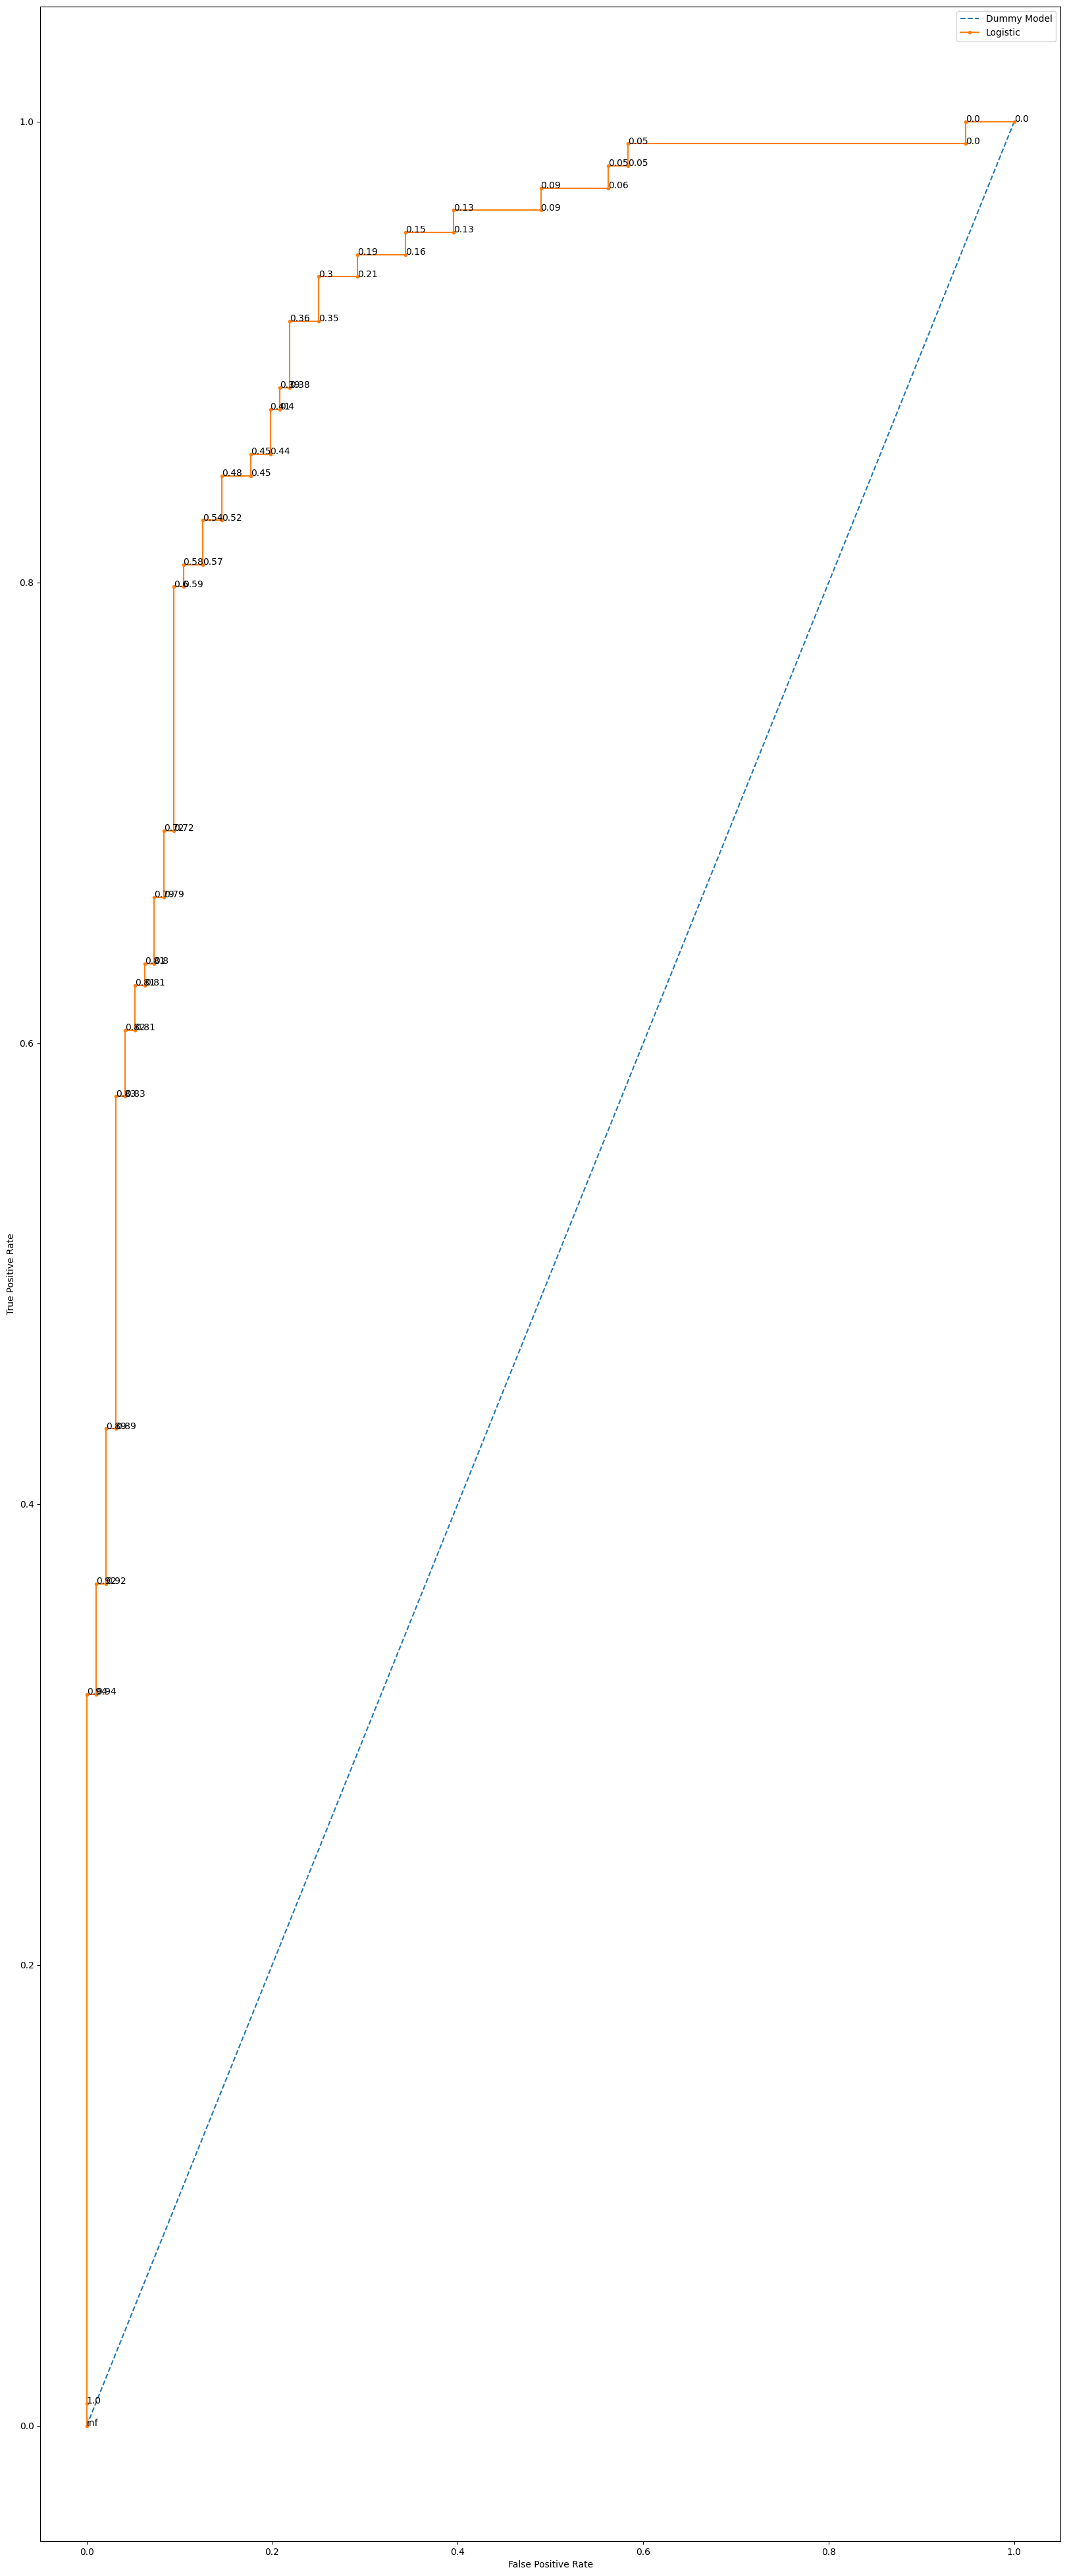

In [20]:
## plot th roc curve for the model

import numpy as np

fig = plt.figure(figsize = (20, 50))
ax = fig.add_subplot(111)

ax.plot(dummy_fpr, dummy_tpr, linestyle = '--', label='Dummy Model')
ax.plot(model_fpr, model_tpr, marker = '.', label = 'Logistic')


for xyz in zip(model_fpr, model_tpr, threshold):
    plt.annotate('%s' % np.round(xyz[2], 2), xy = (xyz[0], xyz[1]))
    
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend()
plt.show()